In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from app.course import Course
from app.database import CourseDatabase

# Enable interactive plots
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Load a Course from Database

In [2]:
# Option 1: Load from database
db = CourseDatabase()
courses = db.conn.execute(
    "SELECT course_id, course_name, total_distance_km, total_elevation_gain_m, course_type FROM courses"
).fetchall()

print("Available courses:")
for i, c in enumerate(courses):
    print(f"  {i}: {c['course_name']} ({c['course_type']}) - {c['total_distance_km']:.1f}km, {c['total_elevation_gain_m']:.0f}m")
    print(c.keys())

Available courses:
  0: Test Course for Integration (test_course) - 1.6km, 71m
['course_id', 'course_name', 'total_distance_km', 'total_elevation_gain_m', 'course_type']
  1: Pedal till ya puke (strava_segment) - 11.2km, 136m
['course_id', 'course_name', 'total_distance_km', 'total_elevation_gain_m', 'course_type']
  2: NF 4832 Climb (strava_segment) - 9.8km, 326m
['course_id', 'course_name', 'total_distance_km', 'total_elevation_gain_m', 'course_type']
  3: Flat Training Loop (sample_course) - 10.8km, 86m
['course_id', 'course_name', 'total_distance_km', 'total_elevation_gain_m', 'course_type']
  4: Mauna Kea Summit (sample_course) - 71.5km, 4387m
['course_id', 'course_name', 'total_distance_km', 'total_elevation_gain_m', 'course_type']


In [3]:
# Choose a course to work with
COURSE_INDEX = 1  # Change this to select a different course

# Get the course_id from the list, then fetch full course data
selected_course = courses[COURSE_INDEX]
course_data = db.get_course(selected_course['course_id'])

# Extract raw GPS data and create DataFrame
course_df = pd.DataFrame(course_data['raw_gps_data'])

print(f"Loaded: {course_data['course_name']}")
print(f"Points: {len(course_df)}")
print(f"Columns: {list(course_df.columns)}")

Loaded: Pedal till ya puke
Points: 984
Columns: ['lat', 'lon', 'ele']


In [4]:
# Create Course object - this processes the raw GPS data (smoothing, gradient, bearing, etc.)
course = Course(course_df)

print(f"Course processed with {len(course.df)} points")
print(f"Gradient range: {course.df['gradient'].min():.1f}% to {course.df['gradient'].max():.1f}%")
print(f"Total distance: {course.df['cumulative_distance'].iloc[-1]/1000:.2f} km")
print(f"Total elevation gain: {course.df['height_gain'].sum():.0f} m")

running process segment
Course processed with 984 points
Gradient range: -5.9% to 16.8%
Total distance: 11.23 km
Total elevation gain: 136 m


## 2. Visualize Raw Course Profile

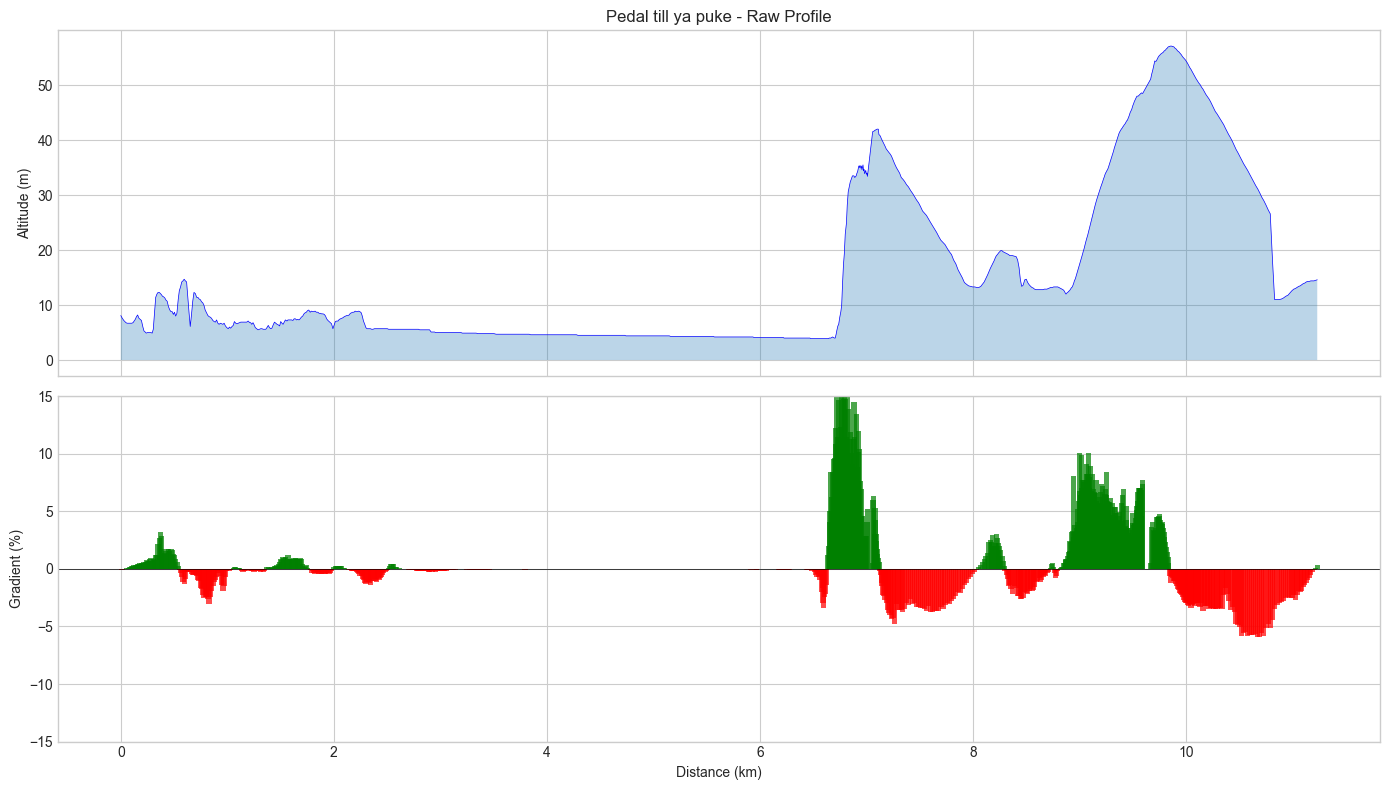

In [5]:
def plot_course_profile(df, title="Course Profile"):
    """Plot elevation and gradient profile."""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    
    # Use cumulative_distance (already in meters)
    cum_dist = df['cumulative_distance'] / 1000  # Convert to km
    
    # Elevation profile
    ax1.fill_between(cum_dist, df['altitude'], alpha=0.3)
    ax1.plot(cum_dist, df['altitude'], 'b-', linewidth=0.5)
    ax1.set_ylabel('Altitude (m)')
    ax1.set_title(title)
    
    # Gradient profile - already in percentage, no need to multiply by 100
    gradient = df['gradient']
    colors = ['green' if g >= 0 else 'red' for g in gradient]
    ax2.bar(cum_dist, gradient, width=0.05, color=colors, alpha=0.7)
    ax2.axhline(y=0, color='black', linewidth=0.5)
    ax2.set_ylabel('Gradient (%)')
    ax2.set_xlabel('Distance (km)')
    ax2.set_ylim(-15, 15)
    
    plt.tight_layout()
    return fig

plot_course_profile(course.df, f"{course_data['course_name']} - Raw Profile")
plt.show()

## 3. Gradient + Bearing Segmentation (Contiguous)

This creates **contiguous segments** based on terrain character changes:
- **Uphill**: gradient > threshold (default: +2%)
- **Flat**: gradient between thresholds  
- **Downhill**: gradient < threshold (default: -2%)
- **Bearing changes**: Large direction changes (e.g., 180° turn) create segment boundaries

Key parameters:
- **uphill_threshold**: Gradient % to classify as uphill (default: 2.0)
- **downhill_threshold**: Gradient % to classify as downhill (default: -2.0)
- **bearing_change_threshold**: Cumulative bearing change that triggers boundary (default: 45°)
- **min_segment_distance**: Minimum segment length to avoid micro-segments (default: 200m)

In [6]:
# Reload course module to pick up new method
import importlib
import app.course as course_module
importlib.reload(course_module)
from app.course import Course

# Recreate course with updated class
course = Course(course_df)

# Segmentation parameters
UPHILL_THRESHOLD = 2.0      # % gradient to be "uphill"
DOWNHILL_THRESHOLD = -2.0   # % gradient to be "downhill"  
BEARING_THRESHOLD = 60.0    # cumulative degrees to trigger boundary
MIN_SEGMENT_DIST = 300.0    # minimum segment length (meters)
SMOOTHING_WINDOW = 21       # smoothing for gradient classification

# Run gradient + bearing segmentation
course.gradient_bearing_segmentation(
    uphill_threshold=UPHILL_THRESHOLD,
    downhill_threshold=DOWNHILL_THRESHOLD,
    bearing_change_threshold=BEARING_THRESHOLD,
    min_segment_distance=MIN_SEGMENT_DIST,
    smoothing_window=SMOOTHING_WINDOW
)

running process segment
Created 9 contiguous segments:
  Seg 0: 4.37km, -0.0%, flat, Σ|bearing|=2702°
  Seg 1: 2.25km, -0.1%, flat, Σ|bearing|=1772°
  Seg 2: 0.47km, +8.3%, uphill, Σ|bearing|=251°
  Seg 3: 0.08km, -0.1%, flat, Σ|bearing|=42°
  Seg 4: 0.68km, -3.4%, downhill, Σ|bearing|=183°
  Seg 5: 1.06km, -0.2%, flat, Σ|bearing|=859°
  Seg 6: 1.03km, +4.7%, uphill, Σ|bearing|=1764°
  Seg 7: 0.09km, -2.7%, downhill, Σ|bearing|=8°
  Seg 8: 1.21km, -3.3%, downhill, Σ|bearing|=441°


/Users/chris/code/pace_yourself/app/course.py:777: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bearing_boundary = df['bearing_change_significant'] & ~df['bearing_change_significant'].shift(1).fillna(False)


,lat,lon,ele,altitude,delta_lat,delta_lon,distance,cumulative_distance,altitude_smoothed,delta_altitude,...,gradient,bearing,bearing_change,raw_gradient,bearing_smoothed,bearing_change_smoothed,terrain_class,bearing_change_significant,segment,segment_terrain
0,47.645194,-122.300915,8.1,8.1,NaN,NaN,0.000000,0.000000,6.818108,NaN,...,0.000000,89.149586,NaN,NaN,81.890724,NaN,flat,True,0,flat
1,47.645195,-122.300815,7.7,7.7,0.000001,0.000100,11.114456,11.114456,6.807555,-0.010553,...,-0.094949,60.729143,-28.420443,-3.598917,82.119901,0.229177,flat,True,0,flat
2,47.645249,-122.300672,7.2,7.2,0.000054,0.000143,16.988279,28.102734,6.801388,-0.006167,...,-0.036304,89.999967,29.270824,-2.943206,82.343347,0.223446,flat,True,0,flat
3,47.645249,-122.300583,7.0,7.0,0.000000,0.000089,9.891371,37.994105,6.799606,-0.001782,...,-0.018013,85.437374,-4.562593,-2.021964,82.561033,0.217686,flat,True,0,flat
4,47.645254,-122.300490,6.8,6.8,0.000005,0.000093,10.350854,48.344960,6.802210,0.002604,...,0.025157,86.497363,1.059989,-1.932208,82.772931,0.211899,flat,True,0,flat
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
979,47.643110,-122.203883,14.4,14.4,-0.000002,0.000130,14.449780,11169.943386,12.570796,-0.073331,...,-0.507489,91.172756,-0.135285,0.692052,89.927950,-1.013050,flat,True,8,downhill
980,47.643108,-122.203738,14.4,14.4,-0.000002,0.000145,16.116688,11186.060074,12.528229,-0.042567,...,-0.264118,93.452702,2.279946,0.000000,88.798195,-1.129755,flat,True,8,downhill
981,47.643103,-122.203615,14.4,14.4,-0.000005,0.000123,13.681387,11199.741461,12.516425,-0.011803,...,-0.086272,85.350423,-8.102278,0.000000,87.544989,-1.253205,flat,True,8,downhill
982,47.643111,-122.203469,14.5,14.5,0.000008,0.000146,16.250635,11215.992096,12.535386,0.018961,...,0.116677,89.355732,4.005309,0.615361,86.161274,-1.383715,flat,True,8,downhill


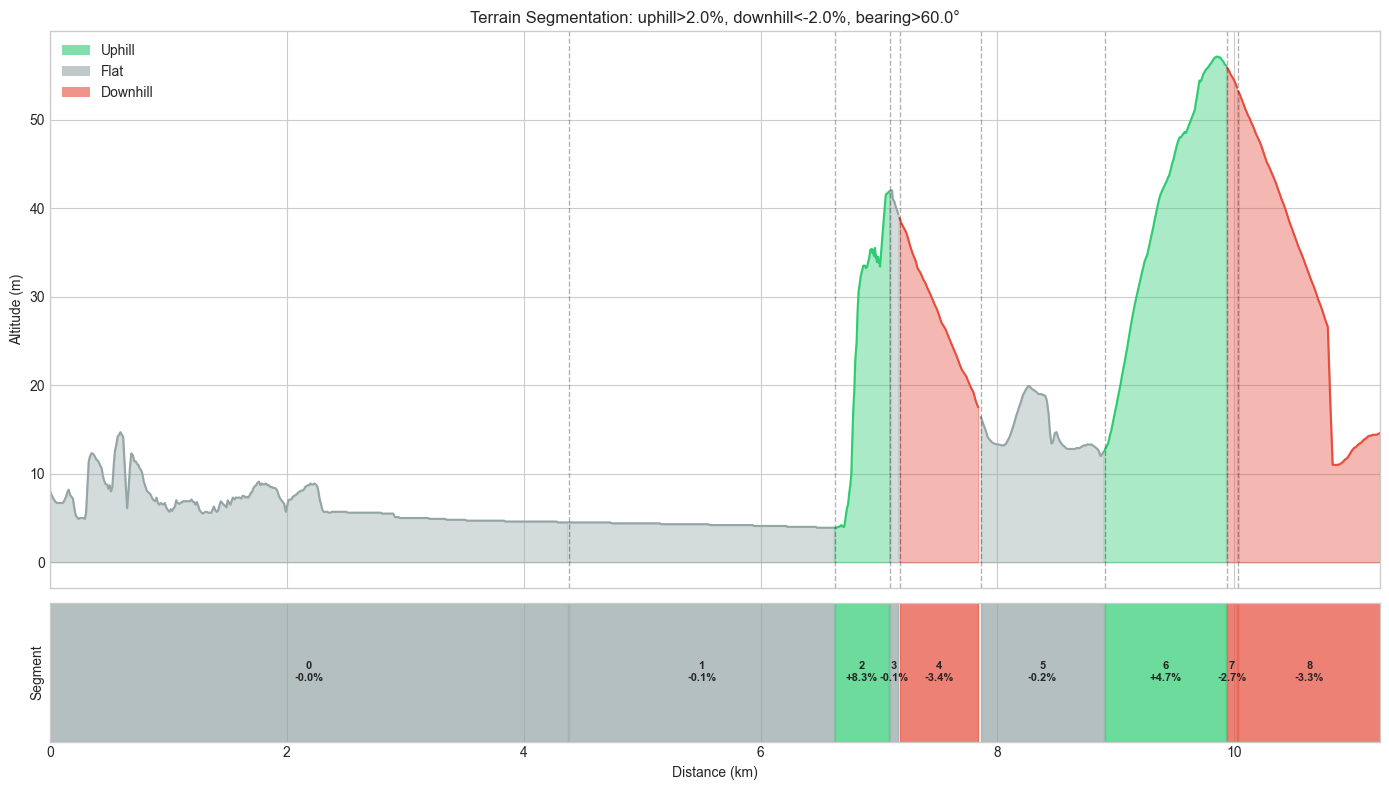

In [7]:
def plot_terrain_segmentation(df, title="Terrain-Based Segmentation"):
    """
    Plot elevation profile with contiguous terrain segments.
    Color-coded by terrain type: green=uphill, gray=flat, red=downhill
    """
    df_sorted = df.sort_values('cumulative_distance').reset_index(drop=True)
    cum_dist = df_sorted['cumulative_distance'] / 1000
    altitude = df_sorted['altitude']
    
    # Color map for terrain types
    terrain_colors = {
        'uphill': '#2ecc71',    # green
        'flat': '#95a5a6',      # gray
        'downhill': '#e74c3c'   # red
    }
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), height_ratios=[4, 1], sharex=True)
    
    # Top: Elevation profile colored by segment
    unique_segments = sorted(df_sorted['segment'].unique())
    
    for seg_id in unique_segments:
        seg_mask = df_sorted['segment'] == seg_id
        seg_indices = df_sorted.index[seg_mask]
        
        # Get contiguous range
        start_idx = seg_indices[0]
        end_idx = seg_indices[-1] + 1  # +1 to include last point
        
        seg_dist = cum_dist.iloc[start_idx:end_idx]
        seg_alt = altitude.iloc[start_idx:end_idx]
        terrain = df_sorted.loc[seg_mask, 'segment_terrain'].iloc[0]
        color = terrain_colors.get(terrain, '#3498db')
        
        ax1.fill_between(seg_dist, seg_alt, alpha=0.4, color=color)
        ax1.plot(seg_dist, seg_alt, color=color, linewidth=1.5)
        
        # Add vertical line at segment boundary
        if seg_id > 0:
            ax1.axvline(x=seg_dist.iloc[0], color='black', linestyle='--', alpha=0.3, linewidth=1)
    
    ax1.set_ylabel('Altitude (m)')
    ax1.set_title(title)
    
    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=terrain_colors['uphill'], alpha=0.6, label='Uphill'),
        Patch(facecolor=terrain_colors['flat'], alpha=0.6, label='Flat'),
        Patch(facecolor=terrain_colors['downhill'], alpha=0.6, label='Downhill')
    ]
    ax1.legend(handles=legend_elements, loc='upper left')
    
    # Bottom: Segment bar with labels
    for seg_id in unique_segments:
        seg_mask = df_sorted['segment'] == seg_id
        seg_indices = df_sorted.index[seg_mask]
        seg_start = cum_dist.iloc[seg_indices[0]]
        seg_end = cum_dist.iloc[seg_indices[-1]]
        
        terrain = df_sorted.loc[seg_mask, 'segment_terrain'].iloc[0]
        avg_grad = df_sorted.loc[seg_mask, 'gradient'].mean()
        color = terrain_colors.get(terrain, '#3498db')
        
        ax2.axvspan(seg_start, seg_end, color=color, alpha=0.7)
        
        # Label with segment number and gradient
        mid_x = (seg_start + seg_end) / 2
        ax2.text(mid_x, 0.5, f'{seg_id}\n{avg_grad:+.1f}%', 
                ha='center', va='center', fontsize=8, fontweight='bold')
    
    ax2.set_xlim(cum_dist.iloc[0], cum_dist.iloc[-1])
    ax2.set_ylim(0, 1)
    ax2.set_yticks([])
    ax2.set_xlabel('Distance (km)')
    ax2.set_ylabel('Segment')
    
    plt.tight_layout()
    return fig

# Visualize the terrain-based segmentation
fig = plot_terrain_segmentation(
    course.df, 
    title=f"Terrain Segmentation: uphill>{UPHILL_THRESHOLD}%, downhill<{DOWNHILL_THRESHOLD}%, bearing>{BEARING_THRESHOLD}°"
)
plt.show()

running process segment
Created 15 contiguous segments:
  Seg 0: 0.26km, +0.3%, flat, Σ|bearing|=217°
  Seg 1: 0.41km, +0.8%, uphill, Σ|bearing|=239°
  Seg 2: 0.26km, -1.5%, downhill, Σ|bearing|=120°
  Seg 3: 3.44km, -0.1%, flat, Σ|bearing|=2127°
  Seg 4: 2.23km, -0.1%, flat, Σ|bearing|=1769°
  Seg 5: 0.50km, +7.7%, uphill, Σ|bearing|=266°
  Seg 6: 0.03km, -0.1%, flat, Σ|bearing|=20°
  Seg 7: 0.97km, -2.6%, downhill, Σ|bearing|=259°
  Seg 8: 0.15km, +2.2%, uphill, Σ|bearing|=111°
  Seg 9: 0.09km, -0.1%, flat, Σ|bearing|=68°
  Seg 10: 0.28km, -1.9%, downhill, Σ|bearing|=193°
  Seg 11: 0.24km, -0.1%, flat, Σ|bearing|=387°
  Seg 12: 1.02km, +4.8%, uphill, Σ|bearing|=1792°
  Seg 13: 0.07km, -1.8%, downhill, Σ|bearing|=7°
  Seg 14: 1.27km, -3.2%, downhill, Σ|bearing|=446°
running process segment
Created 10 contiguous segments:
  Seg 0: 4.37km, -0.0%, flat, Σ|bearing|=2702°
  Seg 1: 2.25km, -0.1%, flat, Σ|bearing|=1772°
  Seg 2: 0.47km, +8.3%, uphill, Σ|bearing|=251°
  Seg 3: 0.08km, -0.1%, 

/Users/chris/code/pace_yourself/app/course.py:777: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bearing_boundary = df['bearing_change_significant'] & ~df['bearing_change_significant'].shift(1).fillna(False)
/Users/chris/code/pace_yourself/app/course.py:777: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bearing_boundary = df['bearing_change_significant'] & ~df['bearing_change_significant'].shift(1).fillna(False)
/Users/chris/code/pace_yourself/app/course.py:777: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and w

  Seg 2: 1.42km, -0.1%, flat, Σ|bearing|=819°
  Seg 3: 1.14km, -0.1%, flat, Σ|bearing|=756°
  Seg 4: 0.74km, -0.0%, flat, Σ|bearing|=456°
  Seg 5: 0.56km, -0.0%, flat, Σ|bearing|=568°
  Seg 6: 0.90km, -0.0%, flat, Σ|bearing|=707°
  Seg 7: 0.74km, -0.3%, flat, Σ|bearing|=495°
  Seg 8: 0.47km, +8.3%, uphill, Σ|bearing|=251°
  Seg 9: 0.08km, -0.1%, flat, Σ|bearing|=42°
  Seg 10: 0.68km, -3.4%, downhill, Σ|bearing|=183°
  Seg 11: 0.40km, +0.6%, flat, Σ|bearing|=168°
  Seg 12: 0.66km, -0.6%, flat, Σ|bearing|=691°
  Seg 13: 0.26km, +6.3%, uphill, Σ|bearing|=535°
  Seg 14: 0.39km, +5.0%, uphill, Σ|bearing|=603°
  Seg 15: 0.39km, +2.9%, uphill, Σ|bearing|=625°
  Seg 16: 1.14km, -3.6%, downhill, Σ|bearing|=315°
  Seg 17: 0.16km, -0.7%, flat, Σ|bearing|=133°


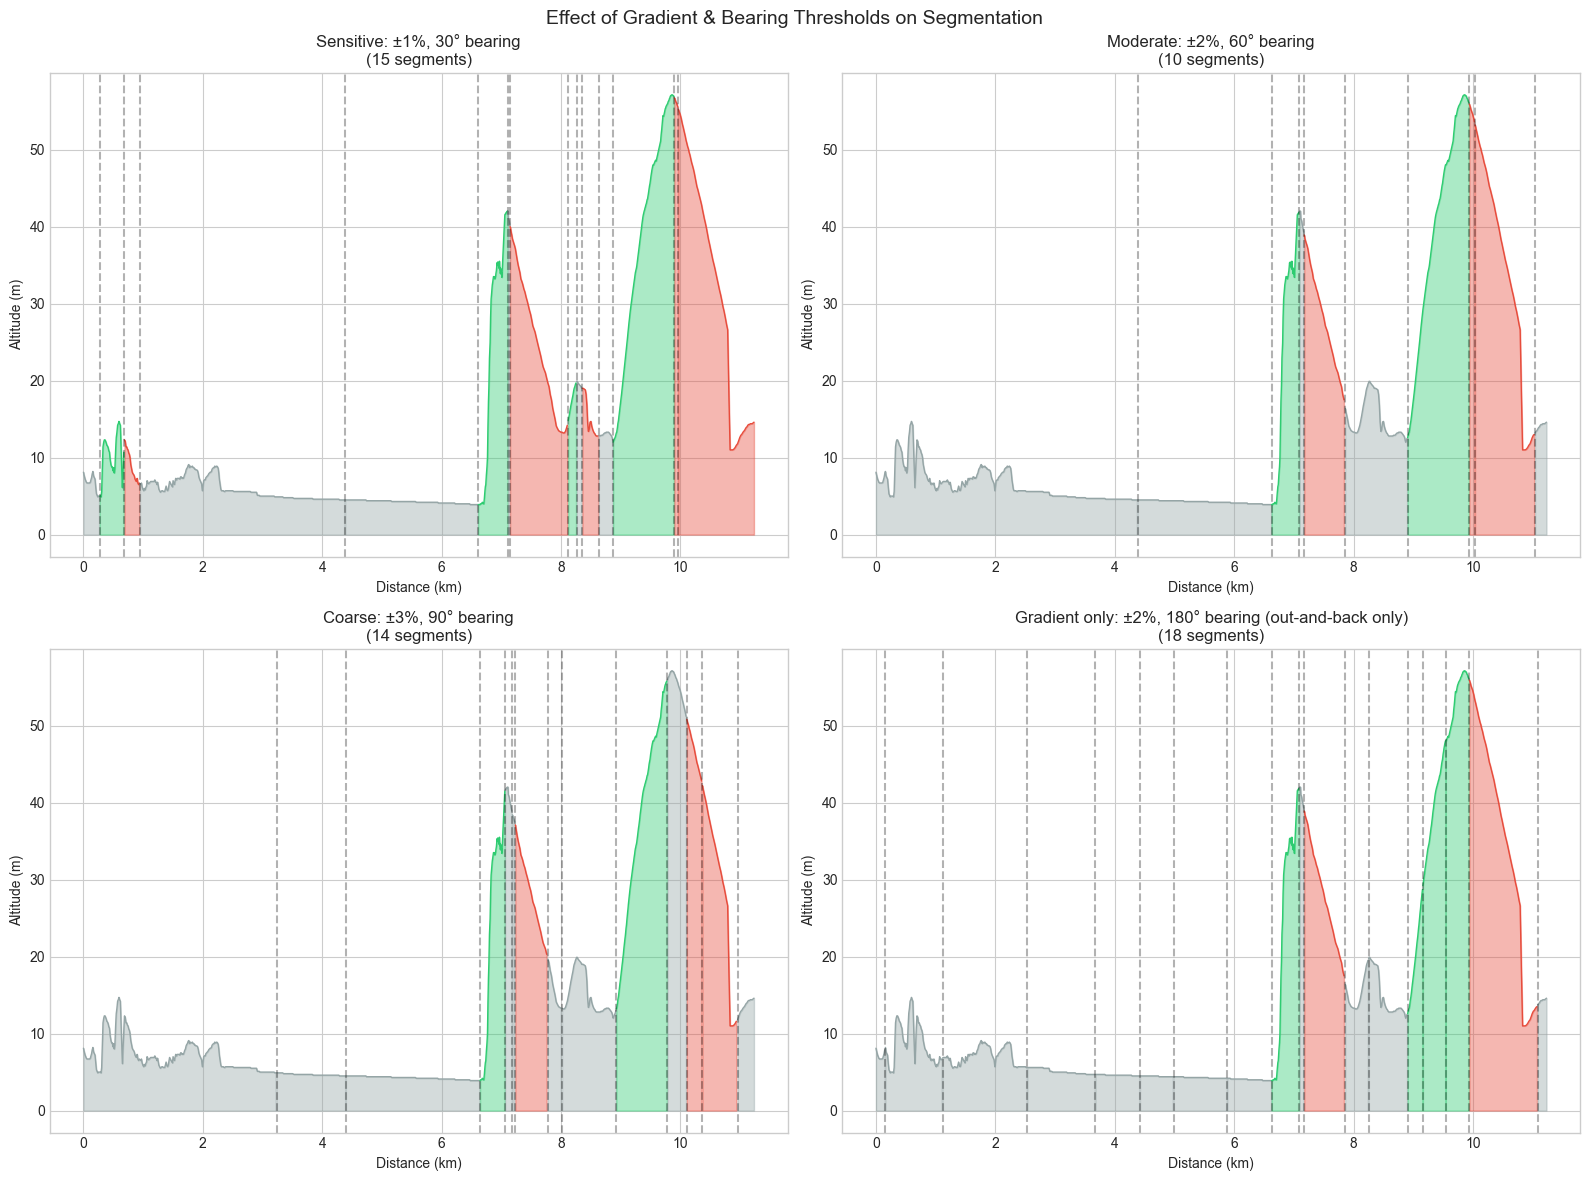

In [8]:
# Experiment with different thresholds
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

terrain_colors = {
    'uphill': '#2ecc71',
    'flat': '#95a5a6', 
    'downhill': '#e74c3c'
}

threshold_configs = [
    (1.0, -1.0, 30.0, "Sensitive: ±1%, 30° bearing"),
    (2.0, -2.0, 60.0, "Moderate: ±2%, 60° bearing"),
    (3.0, -3.0, 90.0, "Coarse: ±3%, 90° bearing"),
    (2.0, -2.0, 180.0, "Gradient only: ±2%, 180° bearing (out-and-back only)")
]

for ax, (up_thresh, down_thresh, bear_thresh, label) in zip(axes.flatten(), threshold_configs):
    test_course = Course(course_df)
    test_course.gradient_bearing_segmentation(
        uphill_threshold=up_thresh,
        downhill_threshold=down_thresh,
        bearing_change_threshold=bear_thresh,
        min_segment_distance=200,
        smoothing_window=21
    )
    
    df_sorted = test_course.df.sort_values('cumulative_distance').reset_index(drop=True)
    cum_dist = df_sorted['cumulative_distance'] / 1000
    altitude = df_sorted['altitude']
    
    for seg_id in sorted(df_sorted['segment'].unique()):
        seg_mask = df_sorted['segment'] == seg_id
        seg_indices = df_sorted.index[seg_mask]
        start_idx, end_idx = seg_indices[0], seg_indices[-1] + 1
        
        terrain = df_sorted.loc[seg_mask, 'segment_terrain'].iloc[0]
        color = terrain_colors.get(terrain, '#3498db')
        
        ax.fill_between(cum_dist.iloc[start_idx:end_idx], altitude.iloc[start_idx:end_idx], 
                       alpha=0.4, color=color)
        ax.plot(cum_dist.iloc[start_idx:end_idx], altitude.iloc[start_idx:end_idx], 
               color=color, linewidth=1)
        
        if seg_id > 0:
            ax.axvline(x=cum_dist.iloc[start_idx], color='black', linestyle='--', alpha=0.3)
    
    n_segs = df_sorted['segment'].nunique()
    ax.set_title(f'{label}\n({n_segs} segments)')
    ax.set_xlabel('Distance (km)')
    ax.set_ylabel('Altitude (m)')

plt.suptitle('Effect of Gradient & Bearing Thresholds on Segmentation', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Clustering-Based Segmentation (Non-Contiguous)

**Note:** This approach groups *similar* points together regardless of position. 
Points at km 2 and km 9 with similar gradient get the same segment ID.
This is useful for analysis but NOT ideal for pacing (where you need contiguous segments).

For pacing, use `gradient_bearing_segmentation()` above instead.

running process segment


/Users/chris/code/pace_yourself/.venv/lib/python3.11/site-packages/sklearn/cluster/_agglomerative.py:586: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)


running process segment


/Users/chris/code/pace_yourself/.venv/lib/python3.11/site-packages/sklearn/cluster/_agglomerative.py:586: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)


running process segment


/Users/chris/code/pace_yourself/.venv/lib/python3.11/site-packages/sklearn/cluster/_agglomerative.py:586: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)


running process segment


/Users/chris/code/pace_yourself/.venv/lib/python3.11/site-packages/sklearn/cluster/_agglomerative.py:586: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)


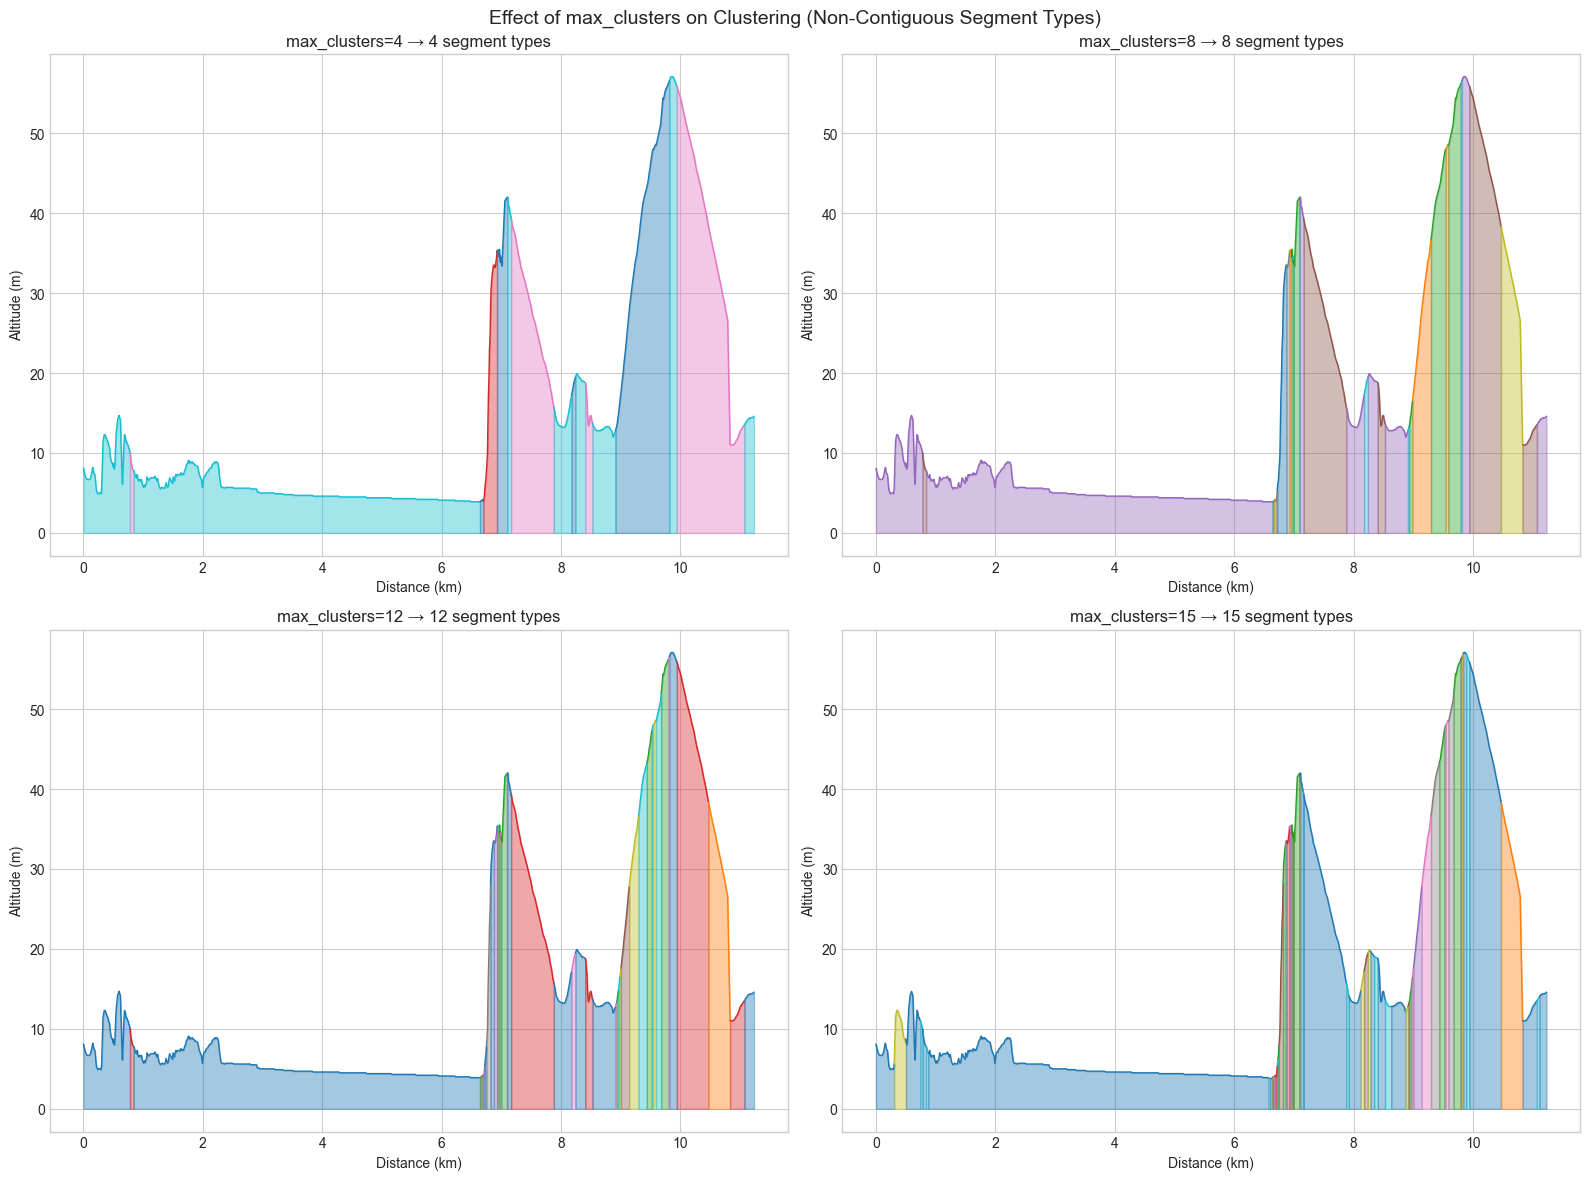

In [9]:
# Test different max_clusters values
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

cluster_values = [4, 8, 12, 15]

for ax, max_clust in zip(axes, cluster_values):
    # Create fresh course and segment
    test_course = Course(course_df)
    test_course.auto_segmentation(max_clusters=max_clust, smoothing_window=11)
    
    # Sort by distance for proper contiguous plotting
    df_sorted = test_course.df.sort_values('cumulative_distance').reset_index(drop=True)
    cum_dist = df_sorted['cumulative_distance'] / 1000
    altitude = df_sorted['altitude']
    segments = df_sorted['segment']
    
    unique_segments = sorted(segments.unique())
    colors = plt.cm.tab10(np.linspace(0, 1, len(unique_segments)))
    segment_colors = {seg: colors[i] for i, seg in enumerate(unique_segments)}
    
    # Plot each contiguous run of points
    prev_seg = None
    seg_start_idx = 0
    
    for i in range(len(df_sorted)):
        seg_id = segments.iloc[i]
        if seg_id != prev_seg:
            if prev_seg is not None and i > seg_start_idx:
                # Plot the previous segment
                ax.fill_between(cum_dist.iloc[seg_start_idx:i+1], 
                               altitude.iloc[seg_start_idx:i+1],
                               alpha=0.4, color=segment_colors[prev_seg])
                ax.plot(cum_dist.iloc[seg_start_idx:i+1], 
                       altitude.iloc[seg_start_idx:i+1],
                       color=segment_colors[prev_seg], linewidth=1)
            seg_start_idx = i
            prev_seg = seg_id
    
    # Plot the last segment
    if prev_seg is not None:
        ax.fill_between(cum_dist.iloc[seg_start_idx:], 
                       altitude.iloc[seg_start_idx:],
                       alpha=0.4, color=segment_colors[prev_seg])
        ax.plot(cum_dist.iloc[seg_start_idx:], 
               altitude.iloc[seg_start_idx:],
               color=segment_colors[prev_seg], linewidth=1)
    
    ax.set_title(f'max_clusters={max_clust} → {len(unique_segments)} segment types')
    ax.set_xlabel('Distance (km)')
    ax.set_ylabel('Altitude (m)')

plt.suptitle('Effect of max_clusters on Clustering (Non-Contiguous Segment Types)', fontsize=14)
plt.tight_layout()
plt.show()

running process segment


/Users/chris/code/pace_yourself/.venv/lib/python3.11/site-packages/sklearn/cluster/_agglomerative.py:586: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)


running process segment


/Users/chris/code/pace_yourself/.venv/lib/python3.11/site-packages/sklearn/cluster/_agglomerative.py:586: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)


running process segment


/Users/chris/code/pace_yourself/.venv/lib/python3.11/site-packages/sklearn/cluster/_agglomerative.py:586: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)


running process segment


/Users/chris/code/pace_yourself/.venv/lib/python3.11/site-packages/sklearn/cluster/_agglomerative.py:586: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)


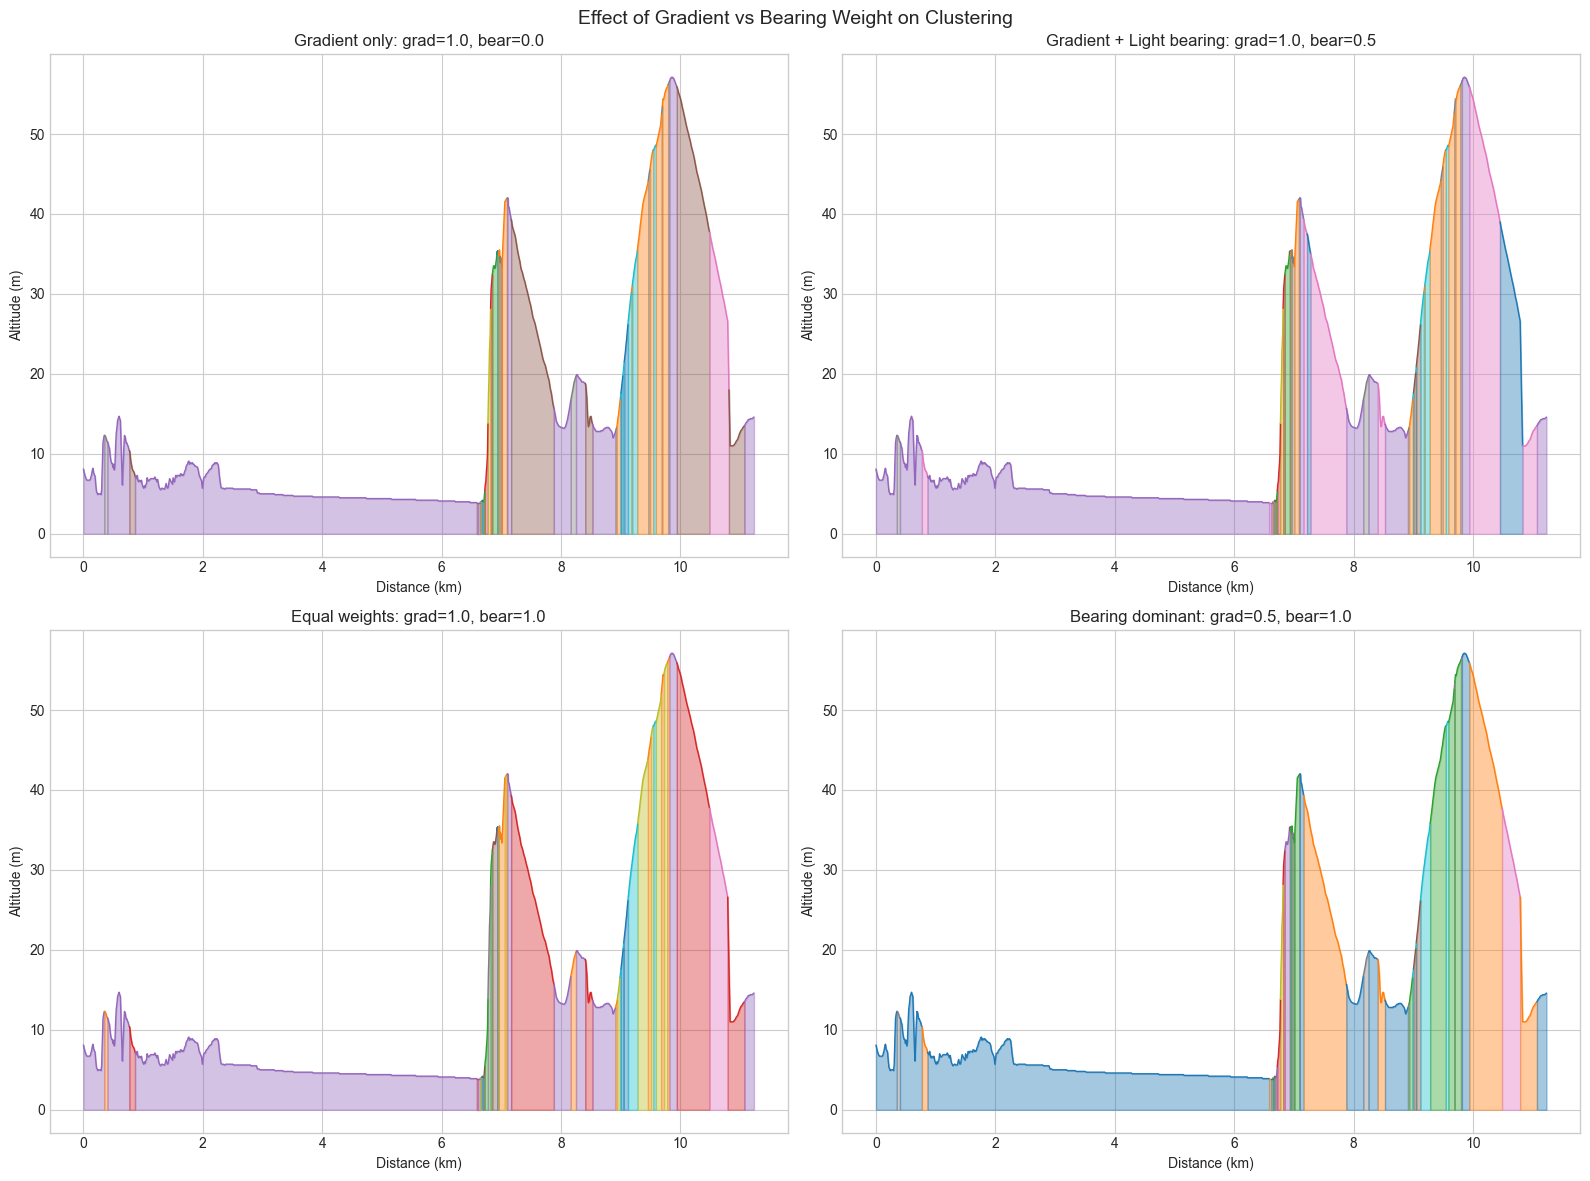

In [10]:
# Test gradient vs bearing weight balance
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

weight_configs = [
    (1.0, 0.0, "Gradient only"),
    (1.0, 0.5, "Gradient + Light bearing"),
    (1.0, 1.0, "Equal weights"),
    (0.5, 1.0, "Bearing dominant")
]

for ax, (g_weight, b_weight, label) in zip(axes.flatten(), weight_configs):
    test_course = Course(course_df)
    test_course.auto_segmentation(
        max_clusters=10,
        gradient_weight=g_weight,
        bearing_weight=b_weight
    )
    
    # Sort by distance for proper contiguous plotting
    df_sorted = test_course.df.sort_values('cumulative_distance').reset_index(drop=True)
    cum_dist = df_sorted['cumulative_distance'] / 1000
    altitude = df_sorted['altitude']
    segments = df_sorted['segment']
    
    unique_segments = sorted(segments.unique())
    colors = plt.cm.tab10(np.linspace(0, 1, len(unique_segments)))
    segment_colors = {seg: colors[i] for i, seg in enumerate(unique_segments)}
    
    # Plot each contiguous run of points
    prev_seg = None
    seg_start_idx = 0
    
    for i in range(len(df_sorted)):
        seg_id = segments.iloc[i]
        if seg_id != prev_seg:
            if prev_seg is not None and i > seg_start_idx:
                ax.fill_between(cum_dist.iloc[seg_start_idx:i+1], 
                               altitude.iloc[seg_start_idx:i+1],
                               alpha=0.4, color=segment_colors[prev_seg])
                ax.plot(cum_dist.iloc[seg_start_idx:i+1], 
                       altitude.iloc[seg_start_idx:i+1],
                       color=segment_colors[prev_seg], linewidth=1)
            seg_start_idx = i
            prev_seg = seg_id
    
    # Plot the last segment
    if prev_seg is not None:
        ax.fill_between(cum_dist.iloc[seg_start_idx:], 
                       altitude.iloc[seg_start_idx:],
                       alpha=0.4, color=segment_colors[prev_seg])
        ax.plot(cum_dist.iloc[seg_start_idx:], 
               altitude.iloc[seg_start_idx:],
               color=segment_colors[prev_seg], linewidth=1)
    
    ax.set_title(f'{label}: grad={g_weight}, bear={b_weight}')
    ax.set_xlabel('Distance (km)')
    ax.set_ylabel('Altitude (m)')

plt.suptitle('Effect of Gradient vs Bearing Weight on Clustering', fontsize=14)
plt.tight_layout()
plt.show()

## 5. Equal Segmentation

Simple alternative: divide course into N equal-distance segments.

In [11]:
def equal_segmentation(df, n_segments):
    """Divide course into N equal-distance segments by assigning segment labels."""
    df = df.copy()
    total_distance = df['cumulative_distance'].iloc[-1]
    segment_distance = total_distance / n_segments
    
    # Assign segment based on cumulative distance
    df['segment'] = (df['cumulative_distance'] / segment_distance).astype(int)
    df['segment'] = df['segment'].clip(upper=n_segments - 1)  # Ensure last points in final segment
    
    return df

# Compare auto vs equal segmentation
n_segs = 10
equal_df = equal_segmentation(course.df.copy(), n_segs)

print(f"Equal segmentation into {n_segs} segments:")
for seg_id in sorted(equal_df['segment'].unique()):
    seg_data = equal_df[equal_df['segment'] == seg_id]
    dist_km = seg_data['distance'].sum() / 1000
    avg_grad = seg_data['gradient'].mean()  # Already in %
    print(f"  Segment {seg_id}: {dist_km:.2f} km, {avg_grad:+.1f}% avg gradient")

Equal segmentation into 10 segments:
  Segment 0: 1.12 km, -0.0% avg gradient
  Segment 1: 1.13 km, +0.1% avg gradient
  Segment 2: 1.12 km, -0.3% avg gradient
  Segment 3: 1.12 km, -0.0% avg gradient
  Segment 4: 1.12 km, -0.0% avg gradient
  Segment 5: 1.12 km, +0.6% avg gradient
  Segment 6: 1.13 km, +2.6% avg gradient
  Segment 7: 1.12 km, +0.2% avg gradient
  Segment 8: 1.13 km, +3.9% avg gradient
  Segment 9: 1.12 km, -3.3% avg gradient


Created 9 contiguous segments:
  Seg 0: 4.37km, -0.0%, flat, Σ|bearing|=2702°
  Seg 1: 2.25km, -0.1%, flat, Σ|bearing|=1772°
  Seg 2: 0.47km, +8.3%, uphill, Σ|bearing|=251°
  Seg 3: 0.08km, -0.1%, flat, Σ|bearing|=42°
  Seg 4: 0.68km, -3.4%, downhill, Σ|bearing|=183°
  Seg 5: 1.06km, -0.2%, flat, Σ|bearing|=859°
  Seg 6: 1.03km, +4.7%, uphill, Σ|bearing|=1764°
  Seg 7: 0.09km, -2.7%, downhill, Σ|bearing|=8°
  Seg 8: 1.21km, -3.3%, downhill, Σ|bearing|=441°


/Users/chris/code/pace_yourself/app/course.py:777: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bearing_boundary = df['bearing_change_significant'] & ~df['bearing_change_significant'].shift(1).fillna(False)


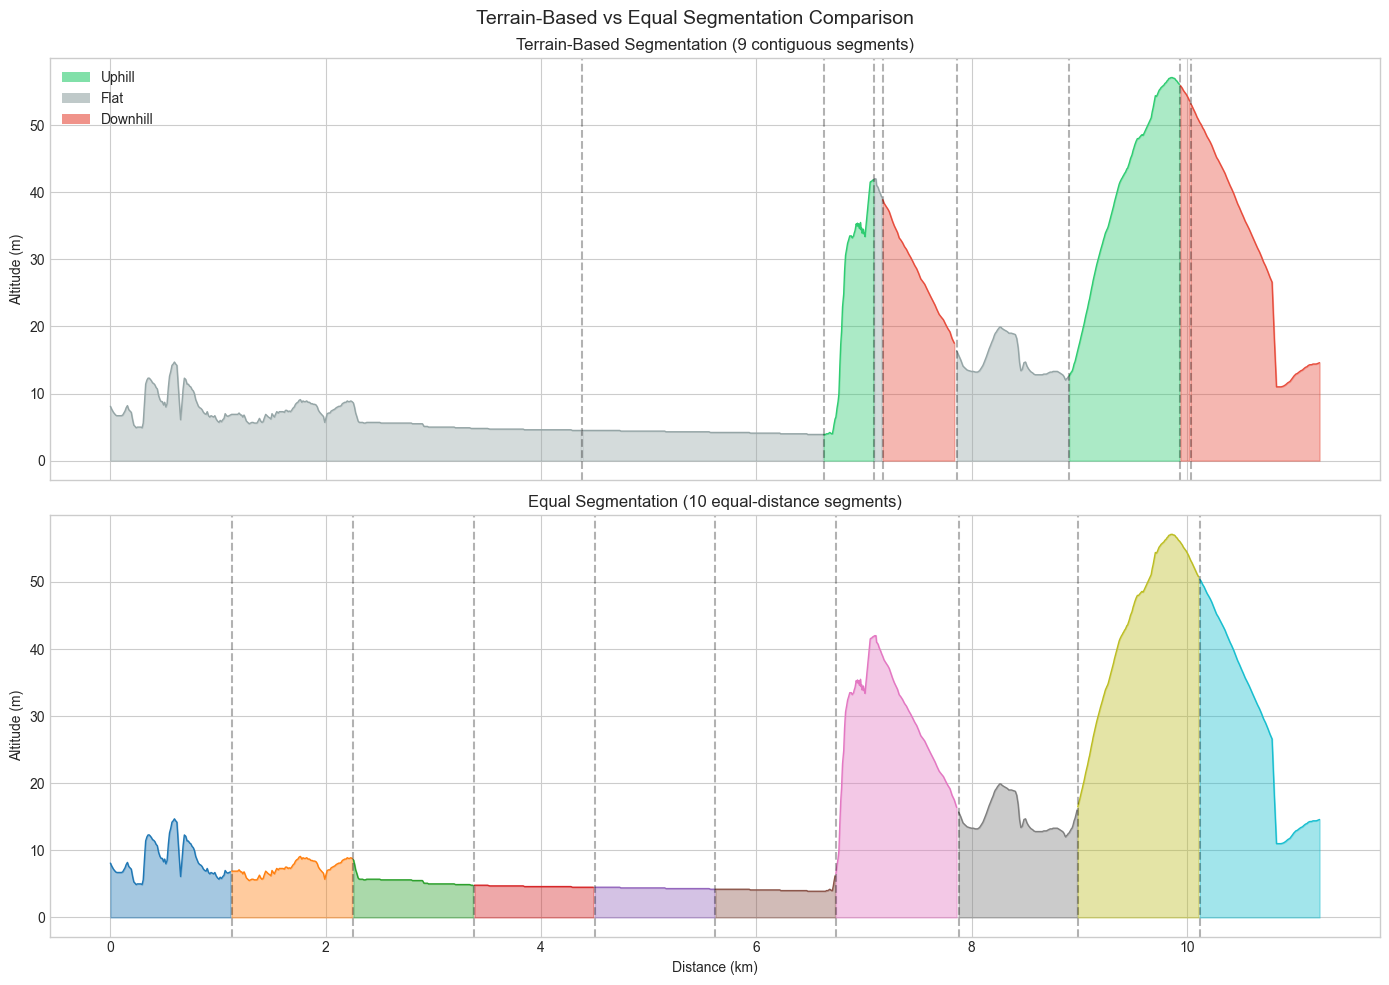

In [12]:
# Visual comparison: Terrain-based vs Equal segmentation
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

terrain_colors = {
    'uphill': '#2ecc71',
    'flat': '#95a5a6', 
    'downhill': '#e74c3c'
}

# Top: Terrain-based segmentation (re-run to ensure clean state)
ax = axes[0]
course.gradient_bearing_segmentation(
    uphill_threshold=2.0, downhill_threshold=-2.0,
    bearing_change_threshold=60.0, min_segment_distance=300
)

df_sorted = course.df.sort_values('cumulative_distance').reset_index(drop=True)
cum_dist = df_sorted['cumulative_distance'] / 1000
altitude = df_sorted['altitude']

for seg_id in sorted(df_sorted['segment'].unique()):
    seg_mask = df_sorted['segment'] == seg_id
    seg_indices = df_sorted.index[seg_mask]
    start_idx, end_idx = seg_indices[0], seg_indices[-1] + 1
    
    terrain = df_sorted.loc[seg_mask, 'segment_terrain'].iloc[0]
    color = terrain_colors.get(terrain, '#3498db')
    
    ax.fill_between(cum_dist.iloc[start_idx:end_idx], altitude.iloc[start_idx:end_idx], 
                   alpha=0.4, color=color)
    ax.plot(cum_dist.iloc[start_idx:end_idx], altitude.iloc[start_idx:end_idx], 
           color=color, linewidth=1)
    
    if seg_id > 0:
        ax.axvline(x=cum_dist.iloc[start_idx], color='black', linestyle='--', alpha=0.3)

ax.set_title(f'Terrain-Based Segmentation ({df_sorted["segment"].nunique()} contiguous segments)')
ax.set_ylabel('Altitude (m)')

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=terrain_colors['uphill'], alpha=0.6, label='Uphill'),
    Patch(facecolor=terrain_colors['flat'], alpha=0.6, label='Flat'),
    Patch(facecolor=terrain_colors['downhill'], alpha=0.6, label='Downhill')
]
ax.legend(handles=legend_elements, loc='upper left')

# Bottom: Equal segmentation
ax = axes[1]
equal_df = equal_segmentation(course.df.copy(), n_segs)
df_sorted_eq = equal_df.sort_values('cumulative_distance').reset_index(drop=True)
cum_dist_eq = df_sorted_eq['cumulative_distance'] / 1000
altitude_eq = df_sorted_eq['altitude']
segments_eq = df_sorted_eq['segment']

unique_segments_eq = sorted(segments_eq.unique())
colors_eq = plt.cm.tab10(np.linspace(0, 1, len(unique_segments_eq)))

for i, seg_id in enumerate(unique_segments_eq):
    seg_mask = segments_eq == seg_id
    seg_indices = df_sorted_eq.index[seg_mask]
    start_idx, end_idx = seg_indices[0], seg_indices[-1] + 1
    
    ax.fill_between(cum_dist_eq.iloc[start_idx:end_idx], altitude_eq.iloc[start_idx:end_idx], 
                   alpha=0.4, color=colors_eq[i])
    ax.plot(cum_dist_eq.iloc[start_idx:end_idx], altitude_eq.iloc[start_idx:end_idx], 
           color=colors_eq[i], linewidth=1)
    
    if seg_id > 0:
        ax.axvline(x=cum_dist_eq.iloc[start_idx], color='black', linestyle='--', alpha=0.3)

ax.set_title(f'Equal Segmentation ({len(unique_segments_eq)} equal-distance segments)')
ax.set_ylabel('Altitude (m)')
ax.set_xlabel('Distance (km)')

plt.suptitle('Terrain-Based vs Equal Segmentation Comparison', fontsize=14)
plt.tight_layout()
plt.show()

## 6. Aggregate Segments

After segmentation, we aggregate to get summary statistics for optimization.

In [13]:
# Re-run auto-segmentation to ensure clean state
course.auto_segmentation(max_clusters=10)

# Aggregate segments - this creates course.course_segments (DataFrame)
# and course.course_segments_aggregated
aggregated = course.course_segments

print("Aggregated segment data:")
print(f"Columns available: {list(aggregated.columns)}")
aggregated

Aggregated segment data:
Columns available: ['segment', 'bearing_mean', 'altitude_mean', 'altitude_min', 'altitude_max', 'gradient_mean', 'height_gain_sum', 'height_loss_sum', 'distance_sum']


/Users/chris/code/pace_yourself/.venv/lib/python3.11/site-packages/sklearn/cluster/_agglomerative.py:586: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)


,segment,bearing_mean,altitude_mean,altitude_min,altitude_max,gradient_mean,height_gain_sum,height_loss_sum,distance_sum
0,0,60.686214,20.486364,4.1,35.4,7.85,8.8,0.4,0.148746
1,1,83.197089,33.455102,3.9,56.4,3.00,13.1,4.7,0.385319
2,2,109.404152,15.011111,5.4,31.6,13.58,12.0,0.0,0.079739
3,3,89.249297,30.478814,3.9,55.9,-3.03,3.7,66.5,1.779475
4,4,96.266514,8.418541,3.9,57.1,-0.09,41.3,45.8,7.644758
5,5,109.597417,27.392857,4.0,35.3,10.86,4.7,0.4,0.113205
6,6,78.661448,32.687500,27.3,37.7,-5.53,0.0,11.0,0.301590
7,7,109.739028,19.640000,13.8,24.9,14.74,14.9,0.0,0.044587
8,8,78.260870,39.689091,4.0,55.8,4.69,25.6,0.1,0.488249
9,9,53.248816,32.805263,4.0,48.6,6.51,11.8,0.5,0.244995


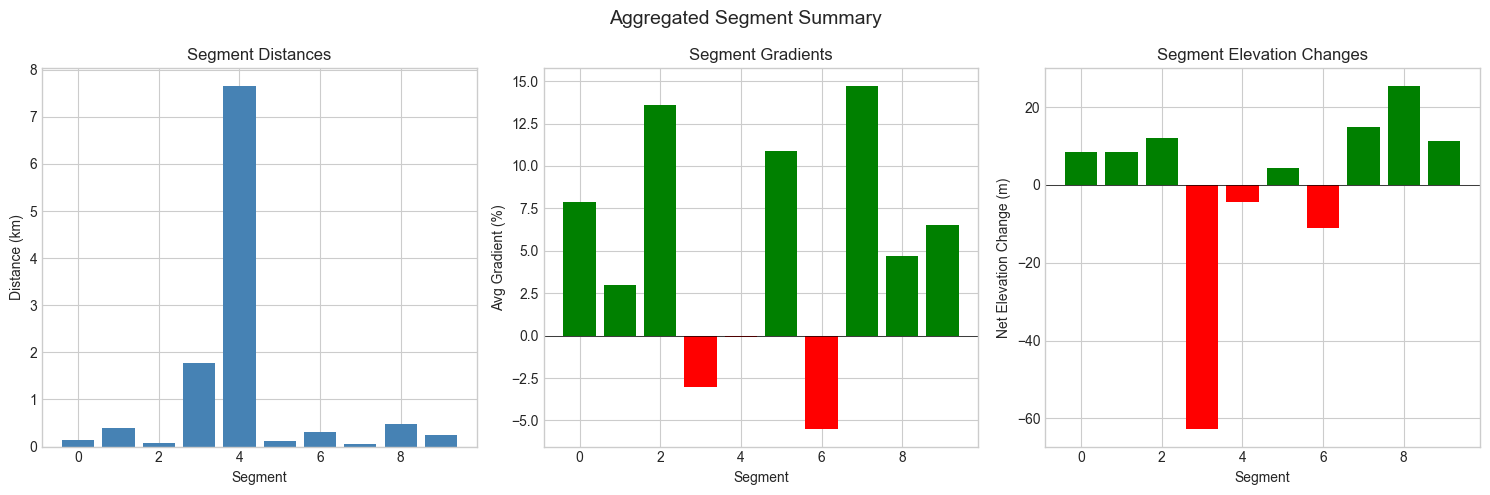

In [14]:
# Visualize aggregated data
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Distance per segment (already in km from aggregate_segments)
ax = axes[0]
ax.bar(aggregated['segment'], aggregated['distance_sum'], color='steelblue')
ax.set_xlabel('Segment')
ax.set_ylabel('Distance (km)')
ax.set_title('Segment Distances')

# Gradient per segment (already in %)
ax = axes[1]
colors = ['green' if g >= 0 else 'red' for g in aggregated['gradient_mean']]
ax.bar(aggregated['segment'], aggregated['gradient_mean'], color=colors)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_xlabel('Segment')
ax.set_ylabel('Avg Gradient (%)')
ax.set_title('Segment Gradients')

# Elevation change per segment
ax = axes[2]
# Calculate net elevation change from height_gain and height_loss
if 'height_gain_sum' in aggregated.columns and 'height_loss_sum' in aggregated.columns:
    net_elev = aggregated['height_gain_sum'] - aggregated['height_loss_sum']
    colors = ['green' if e >= 0 else 'red' for e in net_elev]
    ax.bar(aggregated['segment'], net_elev, color=colors)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_xlabel('Segment')
ax.set_ylabel('Net Elevation Change (m)')
ax.set_title('Segment Elevation Changes')

plt.suptitle('Aggregated Segment Summary', fontsize=14)
plt.tight_layout()
plt.show()

## 7. Key Takeaways

- **max_clusters** controls the maximum granularity - actual segments may be fewer
- **gradient_weight** emphasizes elevation changes (good for hilly courses)
- **bearing_weight** emphasizes direction changes (good for winding courses)
- Auto-segmentation creates segments with consistent terrain characteristics
- Equal segmentation is simpler but may split climbs/descents awkwardly
- Aggregated data is what gets passed to the optimizer